In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.model_selection import train_test_split

bundle = joblib.load("../models/theft_model.joblib")
model, threshold, feature_names = bundle["model"], bundle["threshold"], bundle["features"]

df = pd.read_csv("../data/features.csv")
X = df[feature_names]
y = df["FLAG"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
test_proba = model.predict_proba(X_test)[:, 1]
print("Test customers:", len(X_test), " threshold:", round(threshold, 3))

Test customers: 8458  threshold: 0.187


In [2]:
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)
print(sv.values.shape)      # (customers, features)

(8458, 19)


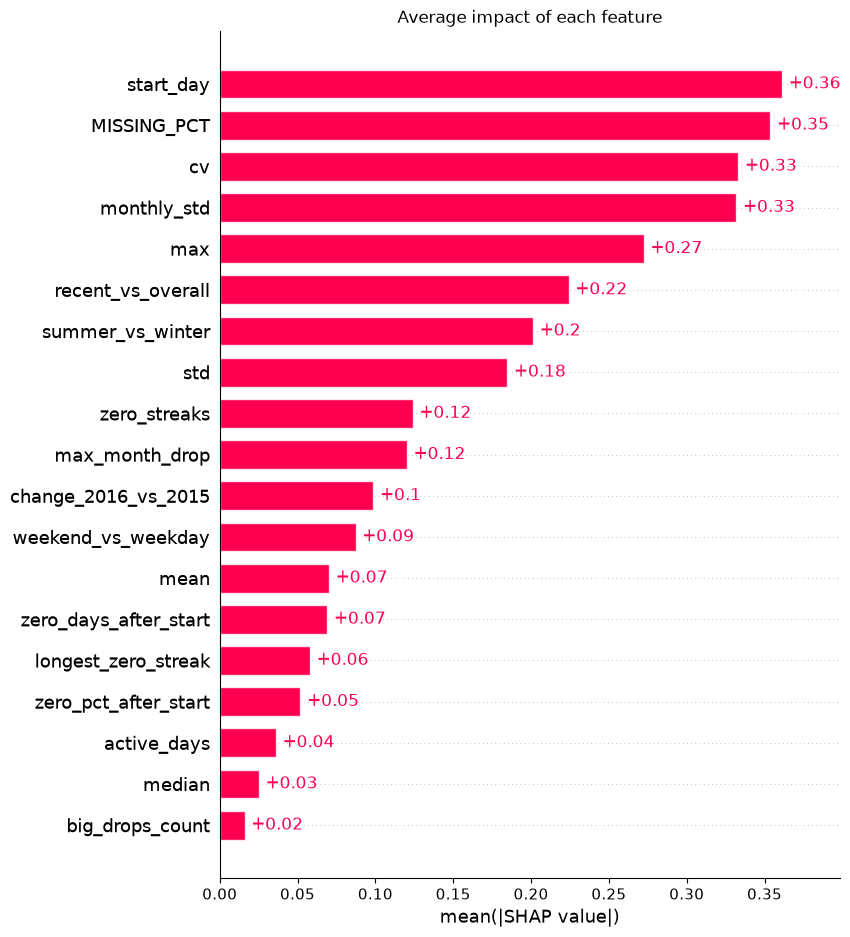

In [3]:
shap.plots.bar(sv, max_display=19, show=False)
plt.title("Average impact of each feature")
plt.savefig("../reports/figures/11_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

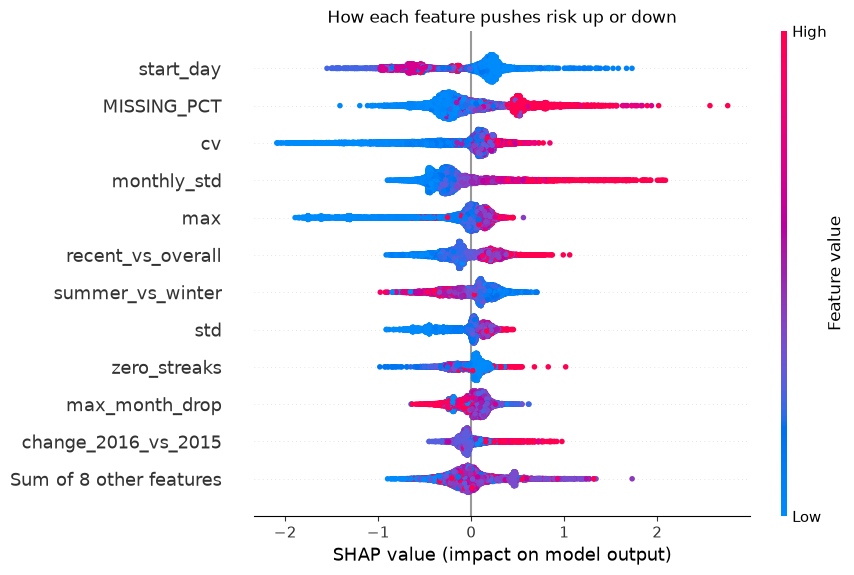

In [4]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("How each feature pushes risk up or down")
plt.savefig("../reports/figures/12_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

caught_thief: risk = 96.1%


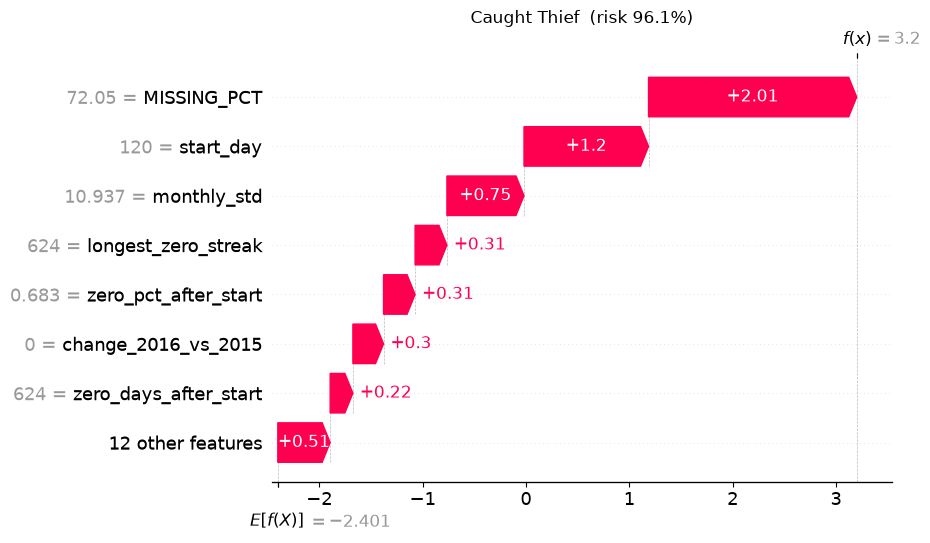

honest: risk = 0.0%


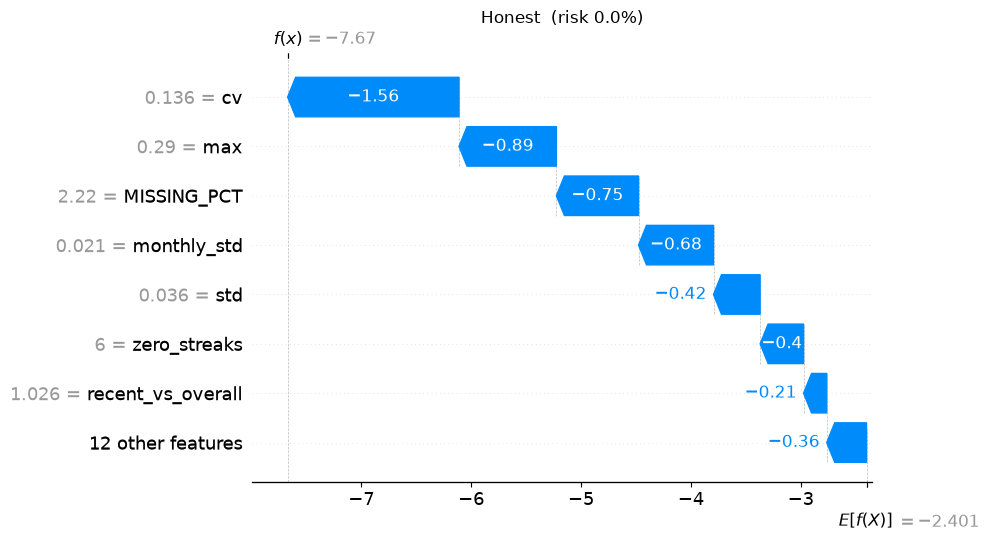

false_alarm: risk = 81.6%


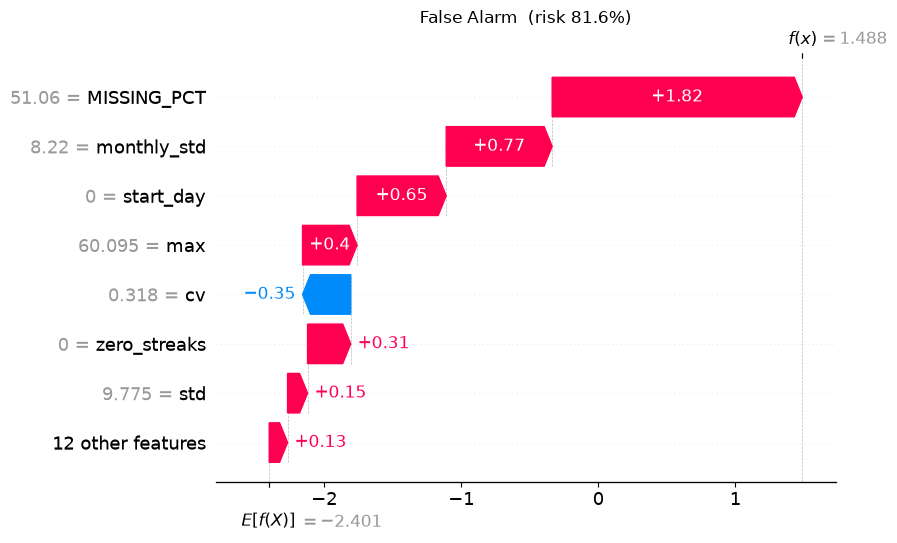

In [5]:
y_arr = y_test.values

# 1) the most suspicious real thief the model caught
thief_pos = np.where(y_arr == 1)[0]
i_thief = thief_pos[np.argmax(test_proba[thief_pos])]

# 2) an honest customer the model correctly cleared (lowest risk)
honest_pos = np.where(y_arr == 0)[0]
i_honest = honest_pos[np.argmin(test_proba[honest_pos])]

# 3) a false alarm: honest customer with the highest risk
i_false = honest_pos[np.argmax(test_proba[honest_pos])]

for name, i in [("caught_thief", i_thief), ("honest", i_honest), ("false_alarm", i_false)]:
    print(f"{name}: risk = {test_proba[i]*100:.1f}%")
    shap.plots.waterfall(sv[i], max_display=8, show=False)
    plt.title(f"{name.replace('_', ' ').title()}  (risk {test_proba[i]*100:.1f}%)")
    plt.savefig(f"../reports/figures/13_waterfall_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
def top_reasons(i, n=3):
    vals = sv.values[i]
    order = np.argsort(vals)[::-1][:n]
    reasons = []
    for j in order:
        if vals[j] > 0:
            reasons.append(f"{feature_names[j]} = {X_test.iloc[i, j]:.2f}  (push +{vals[j]:.2f})")
    return reasons

for name, i in [("Caught thief", i_thief), ("False alarm", i_false)]:
    print(f"\n{name}, risk {test_proba[i]*100:.1f}%. Top reasons:")
    for r in top_reasons(i):
        print("  •", r)


Caught thief, risk 96.1%. Top reasons:
  • MISSING_PCT = 72.05  (push +2.01)
  • start_day = 120.00  (push +1.20)
  • monthly_std = 10.94  (push +0.75)

False alarm, risk 81.6%. Top reasons:
  • MISSING_PCT = 51.06  (push +1.82)
  • monthly_std = 8.22  (push +0.77)
  • start_day = 0.00  (push +0.65)


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_auc(cols):
    m = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                      eval_metric="logloss", n_jobs=-1, random_state=42)
    return cross_val_score(m, X_train[cols], y_train, cv=cv, scoring="roc_auc").mean()

no_start = [c for c in feature_names if c not in ["start_day", "active_days"]]
behaviour_only = [c for c in no_start if c != "MISSING_PCT"]

for name, cols in [("All 19 features", feature_names),
                   ("Without start_day / active_days", no_start),
                   ("Behaviour only (also no MISSING_PCT)", behaviour_only)]:
    print(f"{name:40s} ROC-AUC = {cv_auc(cols):.3f}")

All 19 features                          ROC-AUC = 0.802
Without start_day / active_days          ROC-AUC = 0.784
Behaviour only (also no MISSING_PCT)     ROC-AUC = 0.764
